# Evaluacion Parcial Nro 2 - Deep Learning - DUOC UC



## Integrante
----

- Gabriel Ignacio Cárdenas Valdés

## **Importante: La entrega se debe realizar mediante GitHub**

## Convolutional Neural Networks

En esta actividad, vamos a trabajar con Convolutional Neural Networks para resolver un problema de clasificación de imágenes. En particular, vamos a clasificar imágenes de personajes de la conocida serie de los Simpsons.

Como las CNN profundas son un tipo de modelo bastante avanzado y computacionalmente costoso, se recomienda hacer la práctica en Google Colaboratory con soporte para GPUs. *Nota: para leer las imágenes y estandarizarlas al mismo tamaño se usa la librería opencv, que ya está instalada en Colab.*

<center><img src="https://i.imgur.com/i8zIGqX.jpg" style="text-align: center" height="300px"></center>

El dataset a utilizar consiste en imágenes de personajes de los Simpsons extraídas directamente de capítulos de la serie. Este dataset ha sido recopilado por [Alexandre Attia](http://www.alexattia.fr/) y es más complejo que el dataset de Fashion MNIST. Aparte de tener más clases (vamos a utilizar los 18 personajes con más imágenes), los personajes pueden aparecer en distintas poses, en distintas posiciones de la imagen o con otros personajes en pantalla (si bien el personaje a clasificar siempre aparece en la posición predominante).

## Carga de los datos



In [ ]:
import os, sys, glob, time, itertools, collections
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

SEED = 42
keras.utils.set_random_seed(SEED)   # reproducibilidad (numpy, python y TF)

IN_COLAB = "google.colab" in sys.modules
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))
print("Ejecutando en Colab:", IN_COLAB)

TensorFlow 2.21.0 | Keras 3.13.2
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Ejecutando en Colab: True


In [ ]:
# Descarga del dataset desde Kaggle (publicación original de Alexandre Attia)
!pip install -q kagglehub
import kagglehub
DATA_ROOT = kagglehub.dataset_download("alexattia/the-simpsons-characters-dataset")
print("Datos en:", DATA_ROOT)

def buscar_carpeta_train(raiz):
    # carpeta que contiene una subcarpeta por personaje (p.ej. homer_simpson/ con .jpg)
    for dirpath, dirnames, _ in os.walk(raiz):
        if "homer_simpson" in dirnames and "bart_simpson" in dirnames:
            if glob.glob(os.path.join(dirpath, "homer_simpson", "*.jpg")):
                return dirpath
    raise FileNotFoundError("No se encontró la carpeta de entrenamiento en " + raiz)

def buscar_carpeta_test(raiz):
    # carpeta con archivos sueltos del tipo homer_simpson_12.jpg
    for dirpath, _, filenames in os.walk(raiz):
        if any(f.startswith("homer_simpson_") and f.endswith(".jpg") for f in filenames):
            return dirpath
    raise FileNotFoundError("No se encontró la carpeta de test en " + raiz)

DATASET_TRAIN_PATH = buscar_carpeta_train(DATA_ROOT)
DATASET_TEST_PATH = buscar_carpeta_test(DATA_ROOT)
print("Train:", DATASET_TRAIN_PATH)
print("Test: ", DATASET_TEST_PATH)

os.makedirs("experimentos", exist_ok=True)   # aquí se guardan gráficas, logs y el mejor modelo

Using Colab cache for faster access to the 'the-simpsons-characters-dataset' dataset.
Datos en: /kaggle/input/the-simpsons-characters-dataset
Train: /kaggle/input/the-simpsons-characters-dataset/simpsons_dataset
Test:  /kaggle/input/the-simpsons-characters-dataset/kaggle_simpson_testset/kaggle_simpson_testset


In [ ]:
# Esta variable contiene un mapeo de número de clase a personaje.
# Utilizamos sólo los 18 personajes del dataset que tienen más imágenes.
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}

# Vamos a standarizar todas las imágenes a tamaño 64x64
IMG_SIZE = 64

In [ ]:
def load_train_set(dirname, map_characters, verbose=True):
    """Esta función carga los datos de training en imágenes.

    Como las imágenes tienen tamaños distintos, utilizamos la librería opencv
    para hacer un resize y adaptarlas todas a tamaño IMG_SIZE x IMG_SIZE.
    Además se convierten de BGR (formato de opencv) a RGB para visualizarlas bien.

    Returns:
        X, y: X es un array con todas las imágenes cargadas con tamaño IMG_SIZE x IMG_SIZE
              y es un array con las labels correspondientes a cada imagen
    """
    X_train = []
    y_train = []
    for label, character in map_characters.items():
        files = sorted(os.listdir(os.path.join(dirname, character)))
        images = [file for file in files if file.endswith("jpg")]
        if verbose:
            print("Leyendo {} imágenes encontradas de {}".format(len(images), character))
        for image_name in images:
            image = cv2.imread(os.path.join(dirname, character, image_name))
            image = cv2.cvtColor(cv2.resize(image, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
            X_train.append(image)
            y_train.append(label)
    return np.array(X_train), np.array(y_train)

In [ ]:
def load_test_set(dirname, map_characters, verbose=True):
    """Equivalente a load_train_set pero para los datos de test.
    (Se usa os.path.basename para que funcione también con rutas de Windows.)"""
    X_test = []
    y_test = []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in sorted(glob.glob(os.path.join(dirname, "*.*"))):
        char_name = "_".join(os.path.basename(filename).split("_")[:-1])
        if char_name in reverse_dict:
            image = cv2.imread(filename)
            image = cv2.cvtColor(cv2.resize(image, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
            X_test.append(image)
            y_test.append(reverse_dict[char_name])
    if verbose:
        print("Leídas {} imágenes de test".format(len(X_test)))
    return np.array(X_test), np.array(y_test)

In [ ]:
t0 = time.time()
X, y = load_train_set(DATASET_TRAIN_PATH, MAP_CHARACTERS)
X_t, y_t = load_test_set(DATASET_TEST_PATH, MAP_CHARACTERS)
print(f"\nTrain: {X.shape}, Test: {X_t.shape}  (carga en {time.time()-t0:.0f} s)")

Leyendo 913 imágenes encontradas de abraham_grampa_simpson
Leyendo 623 imágenes encontradas de apu_nahasapeemapetilon
Leyendo 1342 imágenes encontradas de bart_simpson
Leyendo 1193 imágenes encontradas de charles_montgomery_burns
Leyendo 986 imágenes encontradas de chief_wiggum
Leyendo 469 imágenes encontradas de comic_book_guy
Leyendo 457 imágenes encontradas de edna_krabappel
Leyendo 2246 imágenes encontradas de homer_simpson
Leyendo 498 imágenes encontradas de kent_brockman
Leyendo 1206 imágenes encontradas de krusty_the_clown
Leyendo 1354 imágenes encontradas de lisa_simpson
Leyendo 1291 imágenes encontradas de marge_simpson
Leyendo 1079 imágenes encontradas de milhouse_van_houten
Leyendo 1452 imágenes encontradas de moe_szyslak
Leyendo 1454 imágenes encontradas de ned_flanders
Leyendo 358 imágenes encontradas de nelson_muntz
Leyendo 1194 imágenes encontradas de principal_skinner
Leyendo 877 imágenes encontradas de sideshow_bob
Leídas 890 imágenes de test

Train: (18992, 64, 64, 3)

In [ ]:
# Barajamos aleatoriamente los datos. Si no lo hacemos, las imágenes quedan ordenadas
# personaje a personaje (así se leen). La partición train/validation se hace más abajo
# con train_test_split estratificado, que también baraja.
perm = np.random.permutation(len(X))
X, y = X[perm], y[perm]

## 1. Análisis de los datos

Antes de entrenar revisamos cuántas imágenes hay por personaje, cómo lucen y en qué rango están los píxeles.

,personaje,train,test,% train
0,Homer,2246,50,11.8
1,Ned Flanders,1454,49,7.7
2,Moe,1452,50,7.6
3,Lisa,1354,50,7.1
4,Bart,1342,50,7.1
5,Marge,1291,50,6.8
6,Krusty,1206,50,6.4
7,Skinner,1194,50,6.3
8,Mr. Burns,1193,48,6.3
9,Milhouse,1079,49,5.7


Total train: 18992  |  Total test: 890
Desbalance train (máx/mín): 6.3x


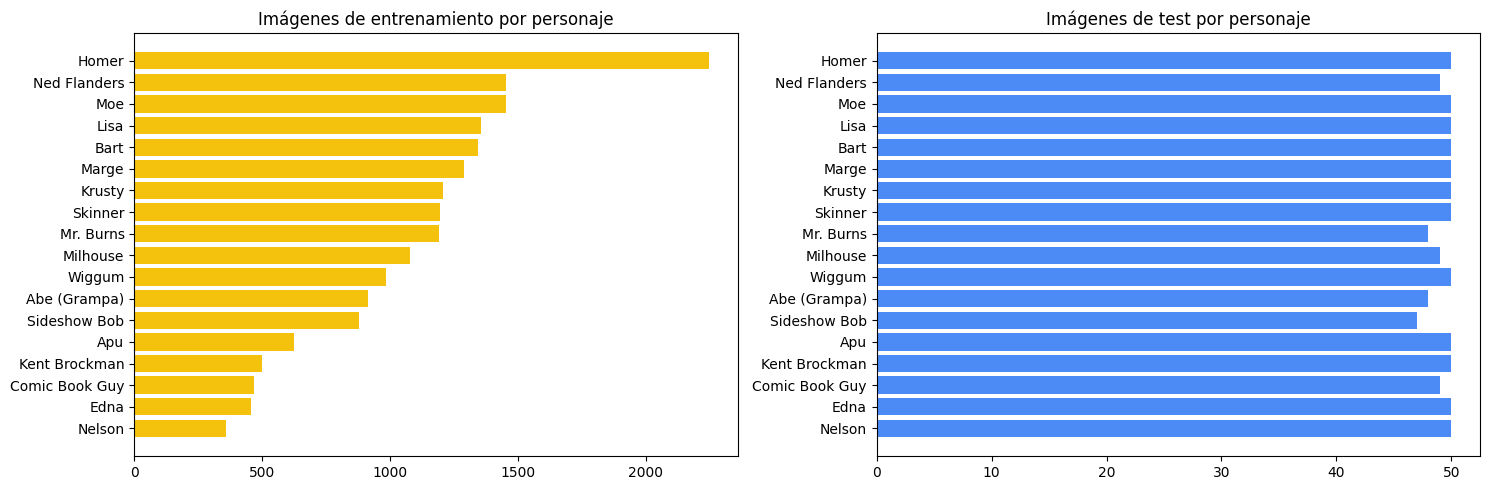

In [ ]:
NAMES = [MAP_CHARACTERS[i] for i in range(len(MAP_CHARACTERS))]
SHORT = [n.split("_")[0].capitalize() if n.split("_")[0] not in ("charles", "chief", "comic", "principal", "sideshow", "kent", "edna", "ned", "abraham")
         else {"charles": "Mr. Burns", "chief": "Wiggum", "comic": "Comic Book Guy", "principal": "Skinner",
               "sideshow": "Sideshow Bob", "kent": "Kent Brockman", "edna": "Edna", "ned": "Ned Flanders",
               "abraham": "Abe (Grampa)"}[n.split("_")[0]] for n in NAMES]

dist = pd.DataFrame({
    "personaje": SHORT,
    "train": np.bincount(y, minlength=18),
    "test": np.bincount(y_t, minlength=18),
})
dist["% train"] = (100 * dist["train"] / dist["train"].sum()).round(1)
display(dist.sort_values("train", ascending=False).reset_index(drop=True))
print(f"Total train: {dist['train'].sum()}  |  Total test: {dist['test'].sum()}")
print(f"Desbalance train (máx/mín): {dist['train'].max() / dist['train'].min():.1f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
d = dist.sort_values("train")
ax[0].barh(d["personaje"], d["train"], color="#f4c20d"); ax[0].set_title("Imágenes de entrenamiento por personaje")
ax[1].barh(d["personaje"], d["test"], color="#4c8bf5"); ax[1].set_title("Imágenes de test por personaje")
plt.tight_layout(); plt.show()

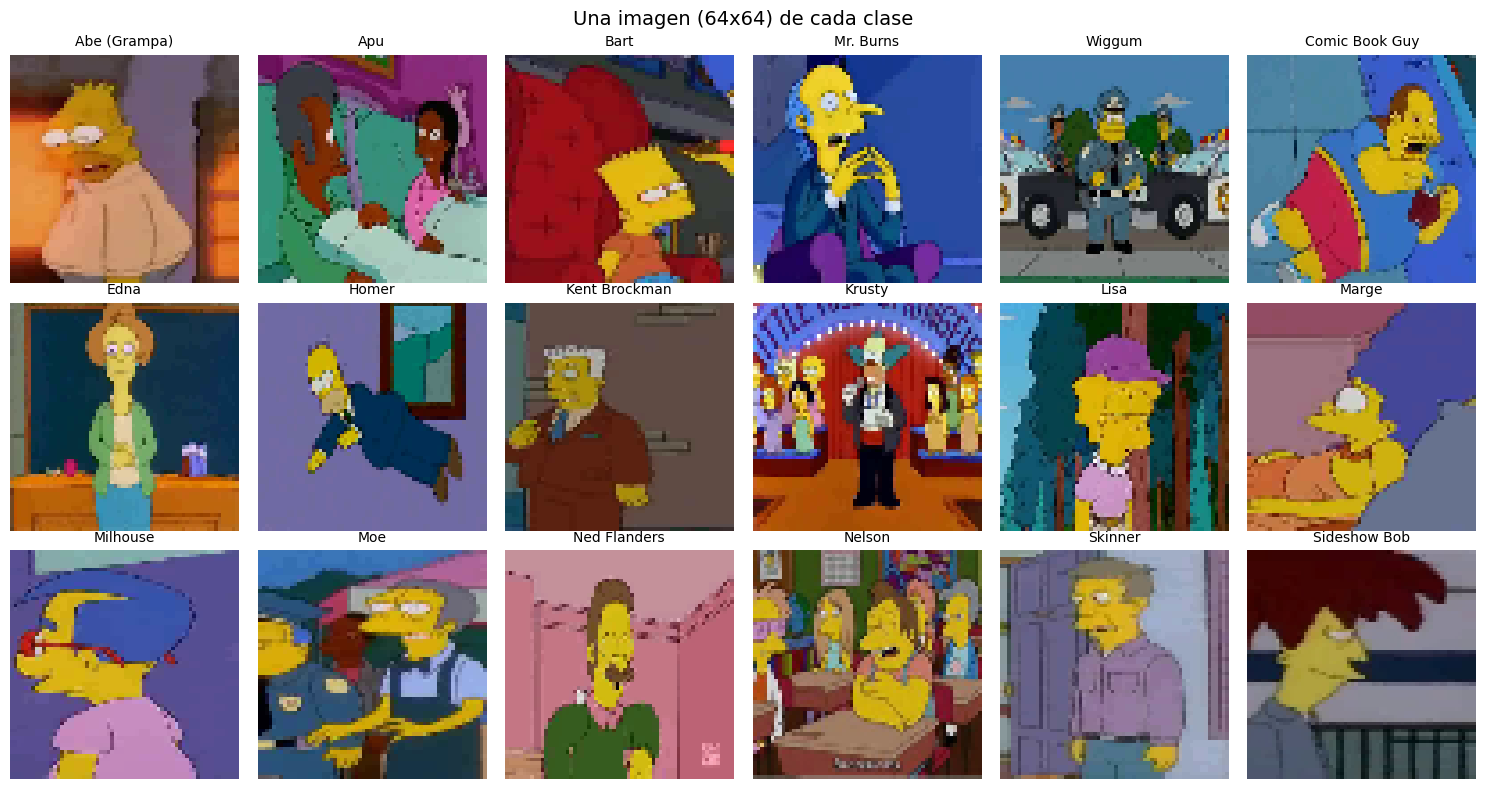

Tipo de dato: uint8 | rango de píxeles: 0 - 255 | media: 104.3


In [ ]:
# Un ejemplo aleatorio de cada personaje
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
rng = np.random.default_rng(SEED)
for i, ax in enumerate(axes.flat):
    idx = rng.choice(np.where(y == i)[0])
    ax.imshow(X[idx]); ax.set_title(SHORT[i], fontsize=10); ax.axis("off")
plt.suptitle("Una imagen (64x64) de cada clase", fontsize=14); plt.tight_layout(); plt.show()

print("Tipo de dato:", X.dtype, "| rango de píxeles:", X.min(), "-", X.max(),
      "| media:", round(X.mean(), 1))

**Observaciones del análisis:**

Se usan **18.992 imágenes de entrenamiento** de 18 personajes y **890 de test** (≈50 por personaje, por lo que el test está balanceado).
- El conjunto de entrenamiento está **desbalanceado** (6,3x entre la clase mayor y la menor): Homer tiene 2.246 imágenes (11,8 %) mientras que Nelson tiene 358 (1,9 %), Edna 457 y Comic Book Guy 469. Es esperable que las clases minoritarias sean las más difíciles.
- Las imágenes son capturas de capítulos: el personaje aparece en distintas poses, tamaños y posiciones, a veces de perfil, de espaldas, parcialmente fuera del cuadro o junto a otros personajes. Esto justifica usar convoluciones (invarianza a la posición) y *data augmentation*.
- Al reducirlas a 64x64 se pierde detalle; muchos personajes comparten la misma piel amarilla, por lo que el modelo debe apoyarse en rasgos como el pelo, la ropa y la forma de la cabeza.
- Los píxeles vienen en `uint8` con rango 0–255 (media ≈104), **no están normalizados**, así que se escalan a [0, 1] antes de entrenar.

## 2. Preprocesamiento

1. **Normalización**: las imágenes vienen en `uint8` (0–255), se escalan a `float32` en [0, 1].
2. **Partición train / validation 80/20 estratificada**: así cada personaje queda representado en la misma proporción en
   ambos conjuntos y la validación es una buena estimación del rendimiento en test (y nos permite detectar *overfitting*).
3. Las etiquetas se dejan como enteros y se usa `sparse_categorical_crossentropy`.

In [ ]:
X_norm = X.astype("float32") / 255.0
X_test = X_t.astype("float32") / 255.0
y_test = y_t

X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)
print("Rango después de normalizar:", X_train.min(), "-", X_train.max())

Train: (15193, 64, 64, 3)  Validation: (3799, 64, 64, 3)  Test: (890, 64, 64, 3)
Rango después de normalizar: 0.0 - 1.0


In [ ]:
RESULTS = {}      # resumen de cada experimento
HISTORIES = {}

def plot_history(h, name, save=True):
    hist = h.history if hasattr(h, "history") else h
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="validation")
    ax[0].set_title(f"{name} - accuracy"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="validation")
    ax[1].set_title(f"{name} - loss"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join("experimentos", f"curvas_{name}.png"), dpi=90)
    plt.show()

def entrenar(model, name, epochs, lr=1e-3, batch_size=64, patience=8, verbose=0):
    """Compila y entrena con Adam + EarlyStopping + ReduceLROnPlateau, y registra métricas."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience,
                                         restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
           keras.callbacks.CSVLogger(os.path.join("experimentos", f"log_{name}.csv"))]   # traza guardada
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                  batch_size=batch_size, callbacks=cbs, verbose=verbose)
    dt = time.time() - t0
    hist = h.history
    best = int(np.argmax(hist["val_accuracy"]))
    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    _, test_acc = model.evaluate(X_test, y_test, verbose=0)
    RESULTS[name] = {"parámetros": model.count_params(), "épocas": len(hist["loss"]),
                     "mejor época": best + 1, "tiempo (min)": round(dt / 60, 1),
                     "train acc": round(hist["accuracy"][best], 4),
                     "val acc": round(val_acc, 4), "test acc": round(test_acc, 4)}
    HISTORIES[name] = hist
    print(f"{name}: {len(hist['loss'])} épocas en {dt/60:.1f} min | "
          f"train acc {hist['accuracy'][best]:.4f} | val acc {val_acc:.4f} | TEST acc {test_acc:.4f}")
    plot_history(hist, name)
    return hist

## 3. Modelo base: red *Fully Connected*

Como punto de comparación entrenamos un perceptrón multicapa que recibe la imagen aplanada (64·64·3 = 12.288 entradas).
Este tipo de red no aprovecha la estructura espacial de la imagen: cada píxel es una entrada independiente,
por lo que un mismo rasgo (p.ej. el pelo de Marge) en otra posición debe aprenderse de nuevo.

Model: "FullyConnected"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,427,922 (24.52 MB)

 Trainable params: 6,427,922 (24.52 MB)

 Non-trainable params: 0 (0.00 B)

1_FullyConnected: 14 épocas en 0.6 min | train acc 0.2385 | val acc 0.3209 | TEST acc 0.2730


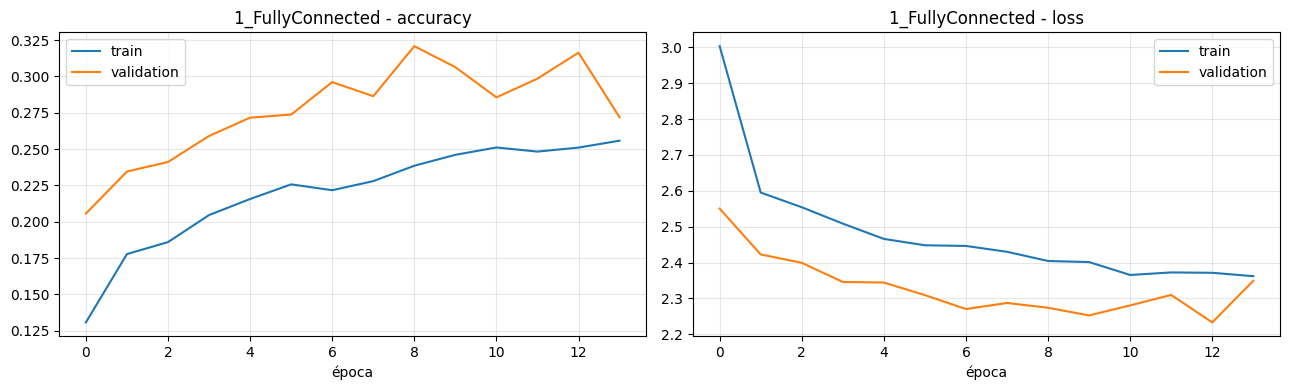

In [ ]:
fc_model = keras.Sequential([
    layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"), layers.Dropout(0.3),
    layers.Dense(256, activation="relu"), layers.Dropout(0.3),
    layers.Dense(18, activation="softmax"),
], name="FullyConnected")
fc_model.summary()
h_fc = entrenar(fc_model, "1_FullyConnected", epochs=30, patience=5)

## 4. CNN simple (2 capas convolucionales)

Primera CNN: dos bloques `Conv2D(3x3) + ReLU + MaxPooling` (32 y 64 filtros), una capa densa de 128 y la salida *softmax*.
Sin regularización, para observar qué tanto mejora la convolución por sí sola y cuánto *overfitting* aparece.

Model: "CNN_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,994 (8.08 MB)

 Trainable params: 2,118,994 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

2_CNN_simple: 18 épocas en 0.9 min | train acc 0.9997 | val acc 0.7697 | TEST acc 0.9483


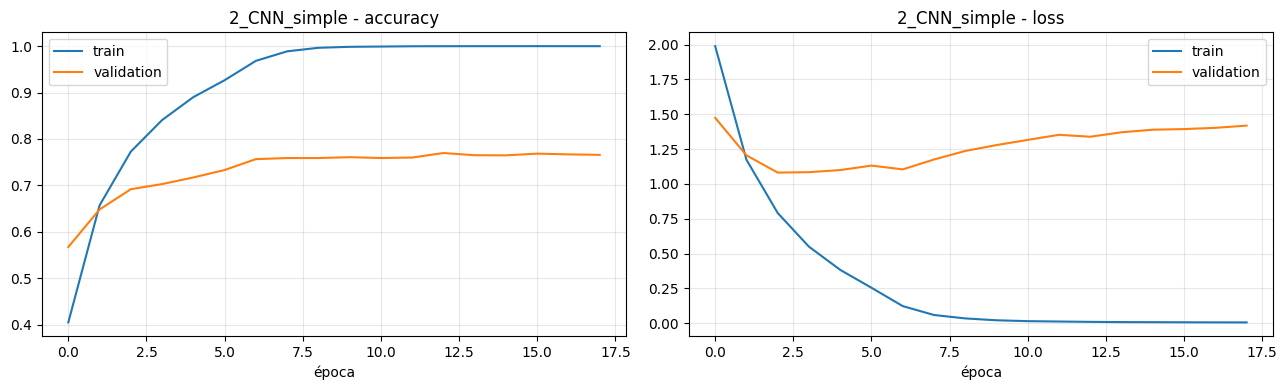

In [ ]:
cnn_simple = keras.Sequential([
    layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(18, activation="softmax"),
], name="CNN_simple")
cnn_simple.summary()
h_simple = entrenar(cnn_simple, "2_CNN_simple", epochs=20, patience=5)

## 5. CNN profunda con *Batch Normalization* y *Dropout*

Arquitectura tipo VGG con 4 bloques convolucionales (32 → 64 → 128 → 256 filtros). Cada bloque tiene:

- 2 × [`Conv2D 3x3` → `BatchNormalization` → `ReLU`]: dos convoluciones seguidas amplían el campo receptivo con pocos
  parámetros; *batch normalization* estabiliza y acelera el entrenamiento (permite usar un *learning rate* mayor).
- `MaxPooling 2x2`: reduce la resolución 64 → 32 → 16 → 8 → 4.
- `Dropout` creciente (0.2 → 0.35) como regularización.

Cabeza: `Dense(256)` + BN + `Dropout(0.5)` y *softmax* de 18 clases.
Optimizador **Adam** (lr = 1e-3), *batch size* 64, `ReduceLROnPlateau` (divide el lr por 2 si la pérdida de validación
se estanca 3 épocas) y `EarlyStopping` sobre la accuracy de validación (restaura los mejores pesos).

Model: "CNN_profunda_BN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 2,229,362 (8.50 MB)

 Trainable params: 2,226,930 (8.50 MB)

 Non-trainable params: 2,432 (9.50 KB)

3_CNN_profunda_BN: 25 épocas en 4.0 min | train acc 0.9925 | val acc 0.9495 | TEST acc 0.9764


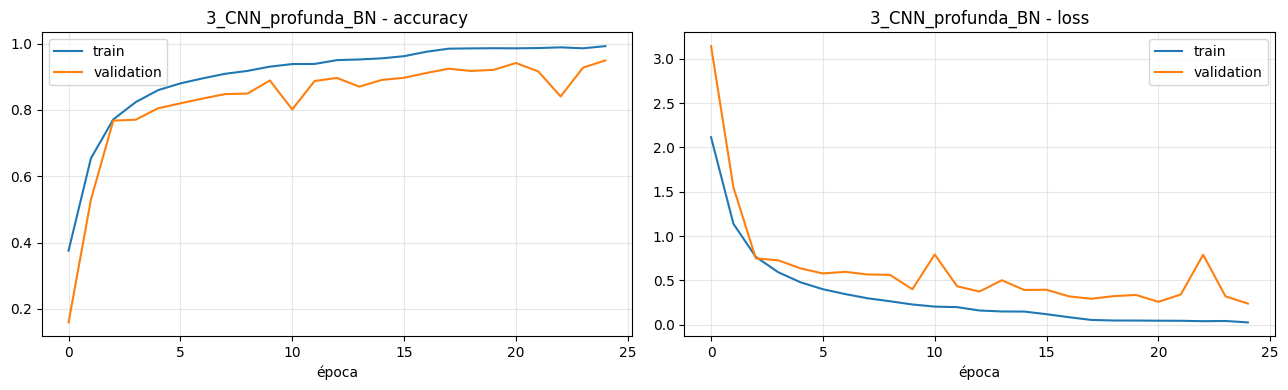

In [ ]:
def bloque_conv(x, filtros, dropout):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(dropout)(x)

def construir_cnn(data_augmentation=None, name="CNN"):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inp) if data_augmentation is not None else inp
    for filtros, drop in [(32, 0.2), (64, 0.25), (128, 0.3), (256, 0.35)]:
        x = bloque_conv(x, filtros, drop)
    x = layers.Flatten()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(18, activation="softmax")(x)
    return keras.Model(inp, out, name=name)

cnn_deep = construir_cnn(name="CNN_profunda_BN")
cnn_deep.summary()
h_deep = entrenar(cnn_deep, "3_CNN_profunda_BN", epochs=25, patience=6)

## 6. Mejor modelo: CNN profunda + *Data Augmentation*

La clase `ImageDataGenerator` fue eliminada en Keras 3; su reemplazo oficial son las **capas de preprocesamiento**
(`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`), que hacen exactamente lo mismo pero dentro del modelo:
se aplican **solo durante el entrenamiento** y se desactivan automáticamente al predecir.

Transformaciones elegidas (moderadas, para no deformar a los personajes):
- volteo horizontal (los personajes aparecen mirando a ambos lados),
- rotación de hasta ±~22°, zoom ±10 % y traslación ±8 % (el personaje no siempre está centrado).

Con esto cada época el modelo ve versiones distintas de las imágenes, lo que reduce el *overfitting* y mejora la generalización.

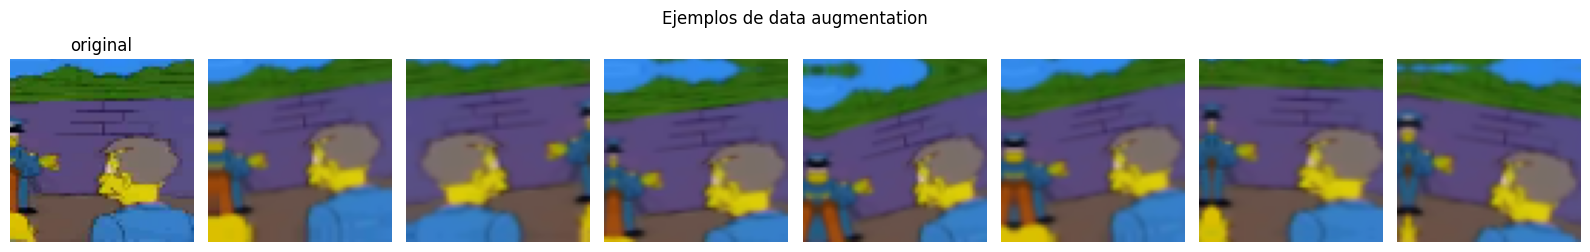

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.08, 0.08),
], name="data_augmentation")

# Visualizamos el efecto sobre una imagen
img = X_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
axes[0].imshow(img[0]); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(np.clip(data_augmentation(img, training=True)[0].numpy(), 0, 1)); ax.axis("off")
plt.suptitle("Ejemplos de data augmentation"); plt.tight_layout(); plt.show()

### Entrenamiento completo del mejor modelo

Se muestra la traza completa de entrenamiento (una línea por época). Se permite entrenar más épocas, ya que con
*augmentation* el modelo tarda más en converger pero sobreajusta mucho menos.

Model: "CNN_profunda_BN_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,229,362 (8.50 MB)

 Trainable params: 2,226,930 (8.50 MB)

 Non-trainable params: 2,432 (9.50 KB)

Epoch 1/45
238/238 - 24s - 103ms/step - accuracy: 0.3213 - loss: 2.3453 - val_accuracy: 0.2506 - val_loss: 2.6099 - learning_rate: 0.0010
Epoch 2/45
238/238 - 14s - 60ms/step - accuracy: 0.6056 - loss: 1.3147 - val_accuracy: 0.6044 - val_loss: 1.2931 - learning_rate: 0.0010
Epoch 3/45
238/238 - 14s - 60ms/step - accuracy: 0.7170 - loss: 0.9454 - val_accuracy: 0.6136 - val_loss: 1.3898 - learning_rate: 0.0010
Epoch 4/45
238/238 - 14s - 60ms/step - accuracy: 0.7733 - loss: 0.7524 - val_accuracy: 0.6552 - val_loss: 1.3681 - learning_rate: 0.0010
Epoch 5/45
238/238 - 14s - 60ms/step - accuracy: 0.8079 - loss: 0.6369 - val_accuracy: 0.7405 - val_loss: 0.9066 - learning_rate: 0.0010
Epoch 6/45
238/238 - 14s - 60ms/step - accuracy: 0.8286 - loss: 0.5754 - val_accuracy: 0.8071 - val_loss: 0.6514 - learning_rate: 0.0010
Epoch 7/45
238/238 - 14s - 60ms/step - accuracy: 0.8474 - loss: 0.5040 - val_accuracy: 0.7781 - val_loss: 0.8268 - learning_rate: 0.0010
Epoch 8/45
238/238 - 14s - 60ms/step - a

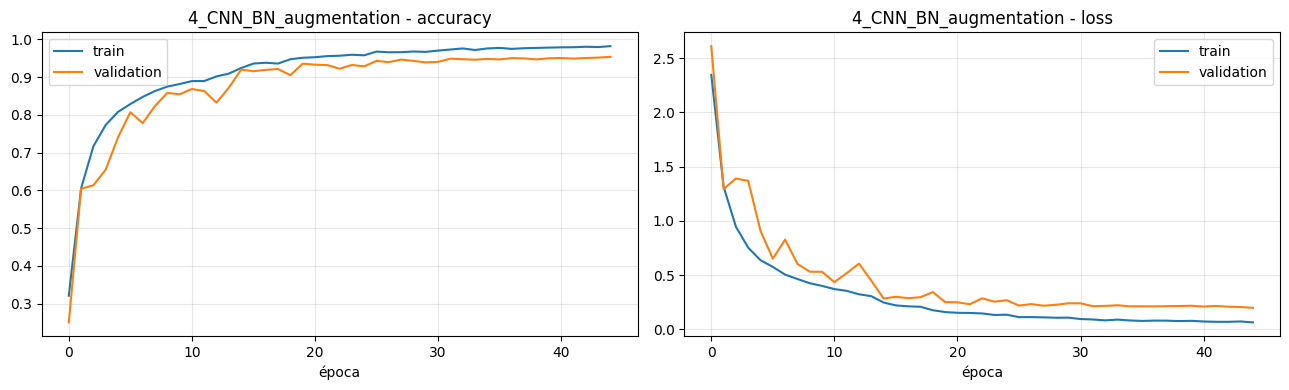

In [ ]:
best_model = construir_cnn(data_augmentation, name="CNN_profunda_BN_augmentation")
best_model.summary()
h_best = entrenar(best_model, "4_CNN_BN_augmentation", epochs=45, patience=10, verbose=2)
best_model.save(os.path.join("experimentos", "mejor_modelo.keras"))   # modelo completo para reutilizar

## 7. Comparación de los modelos

,parámetros,épocas,mejor época,tiempo (min),train acc,val acc,test acc,gap train-val
1_FullyConnected,6427922.0,14.0,9.0,0.6,0.2385,0.3209,0.2730,-0.0824
2_CNN_simple,2118994.0,18.0,13.0,0.9,0.9997,0.7697,0.9483,0.2300
3_CNN_profunda_BN,2229362.0,25.0,25.0,4.0,0.9925,0.9495,0.9764,0.0430
4_CNN_BN_augmentation,2229362.0,45.0,45.0,10.9,0.9819,0.9537,0.9843,0.0282


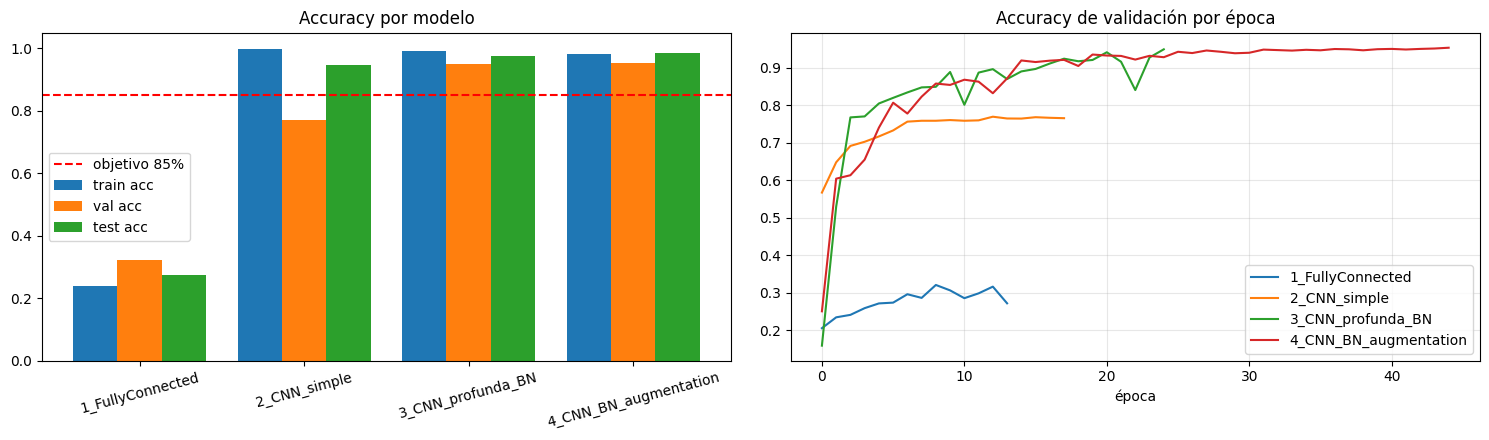

In [ ]:
res = pd.DataFrame(RESULTS).T
res["gap train-val"] = (res["train acc"] - res["val acc"]).round(4)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(res)); w = 0.27
for i, col in enumerate(["train acc", "val acc", "test acc"]):
    ax[0].bar(x + (i - 1) * w, res[col].astype(float), w, label=col)
ax[0].axhline(0.85, color="red", ls="--", label="objetivo 85%")
ax[0].set_xticks(x); ax[0].set_xticklabels(res.index, rotation=15); ax[0].set_ylim(0, 1.05)
ax[0].legend(); ax[0].set_title("Accuracy por modelo")
for name, hist in HISTORIES.items():
    ax[1].plot(hist["val_accuracy"], label=name)
ax[1].set_title("Accuracy de validación por época"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join("experimentos", "comparacion_modelos.png"), dpi=90); plt.show()

**Análisis de la comparación:**

- **Fully Connected (27,3 % en test, 32,1 % en validación):** con 6,4 millones de parámetros es el modelo más grande y, sin embargo, el peor. Al aplanar la imagen pierde la estructura espacial: un mismo rasgo en otra posición es una entrada distinta. Ni siquiera logra ajustar el entrenamiento (23,9 % de accuracy en train, por debajo de validación porque el *dropout* solo actúa al entrenar), lo que muestra que no es una arquitectura adecuada para este problema.
- **CNN simple (94,8 % en test, 77,0 % en validación):** solo dos capas convolucionales más que triplican la accuracy de la FC en test con un tercio de los parámetros. Pero sobreajusta muy rápido: llega a 99,97 % en train mientras la validación se estanca cerca de 77 % (brecha de 23 puntos).
- **CNN profunda + BatchNorm + Dropout (97,6 % en test, 95,0 % en validación):** más profundidad (8 convoluciones) da más capacidad para aprender rasgos jerárquicos, y *batch normalization* + *dropout* reducen la brecha train–validación a 4,3 puntos. Es el salto más grande del estudio: +18 puntos en validación respecto de la CNN simple.
- **CNN profunda + *data augmentation* (98,4 % en test, 95,4 % en validación): mejor modelo.** Supera al anterior en test (unas 7 imágenes más bien clasificadas) y en validación, y tiene la **menor brecha train–validación (2,8 puntos)**, es decir, es el que mejor generaliza. Con *augmentation* el modelo converge más lento: completó las 45 épocas sin que se activara el *EarlyStopping* (mejor época = 45), por lo que más épocas podrían mejorarlo algo. `ReduceLROnPlateau` bajó el *learning rate* cinco veces (de 1e-3 a 3,1e-5), lo que estabilizó la validación al final.
- Como advierte el enunciado, **el test es más "fácil" que la validación**: todos los modelos convolucionales obtienen más accuracy en test que en validación, por lo que la validación es la métrica más honesta para compararlos.

## 8. Evaluación del mejor modelo en el conjunto de test

In [ ]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy en TEST: {test_acc:.4f}   (loss {test_loss:.4f})")
print("Objetivo >= 85%:", "CUMPLIDO" if test_acc >= 0.85 else "NO cumplido")

y_prob = best_model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)
print()
print(classification_report(y_test, y_pred, target_names=SHORT, digits=3))

Accuracy en TEST: 0.9843   (loss 0.0740)
Objetivo >= 85%: CUMPLIDO

                precision    recall  f1-score   support

  Abe (Grampa)      1.000     0.979     0.989        48
           Apu      0.980     1.000     0.990        50
          Bart      1.000     0.980     0.990        50
     Mr. Burns      0.960     1.000     0.980        48
        Wiggum      0.980     0.980     0.980        50
Comic Book Guy      0.980     0.980     0.980        49
          Edna      1.000     0.960     0.980        50
         Homer      0.962     1.000     0.980        50
 Kent Brockman      1.000     0.960     0.980        50
        Krusty      1.000     1.000     1.000        50
          Lisa      0.980     1.000     0.990        50
         Marge      0.980     1.000     0.990        50
      Milhouse      1.000     0.980     0.990        49
           Moe      0.980     0.980     0.980        50
  Ned Flanders      1.000     0.980     0.990        49
        Nelson      0.979     0.940

,personaje,precision,recall,f1,soporte test,imgs train
0,Nelson,0.979,0.940,0.959,50,358
1,Mr. Burns,0.960,1.000,0.980,48,1193
2,Edna,1.000,0.960,0.980,50,457
3,Comic Book Guy,0.980,0.980,0.980,49,469
4,Kent Brockman,1.000,0.960,0.980,50,498
5,Moe,0.980,0.980,0.980,50,1452
6,Wiggum,0.980,0.980,0.980,50,986
7,Homer,0.962,1.000,0.980,50,2246
8,Skinner,0.962,1.000,0.980,50,1194
9,Abe (Grampa),1.000,0.979,0.989,48,913


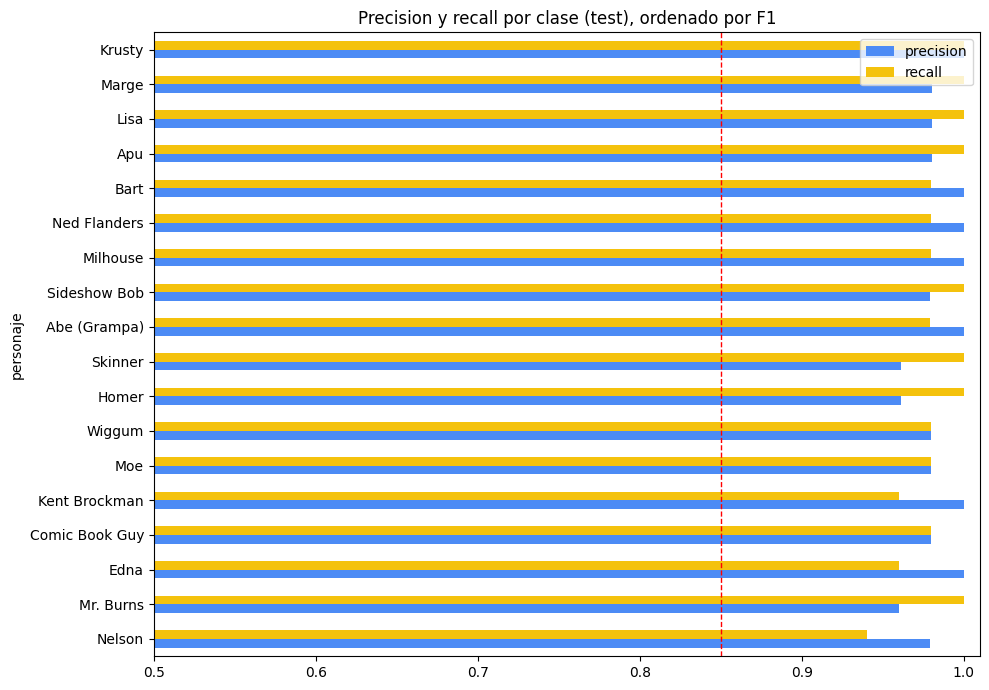

In [ ]:
p, r, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=range(18))
metricas = pd.DataFrame({"personaje": SHORT, "precision": p, "recall": r, "f1": f1, "soporte test": sup,
                         "imgs train": np.bincount(y, minlength=18)}).sort_values("f1")
display(metricas.round(3).reset_index(drop=True))

m = metricas.set_index("personaje")[["precision", "recall"]]
m.plot.barh(figsize=(10, 7), color=["#4c8bf5", "#f4c20d"])
plt.axvline(0.85, color="red", ls="--", lw=1); plt.xlim(0.5, 1.01)
plt.title("Precision y recall por clase (test), ordenado por F1"); plt.tight_layout(); plt.show()

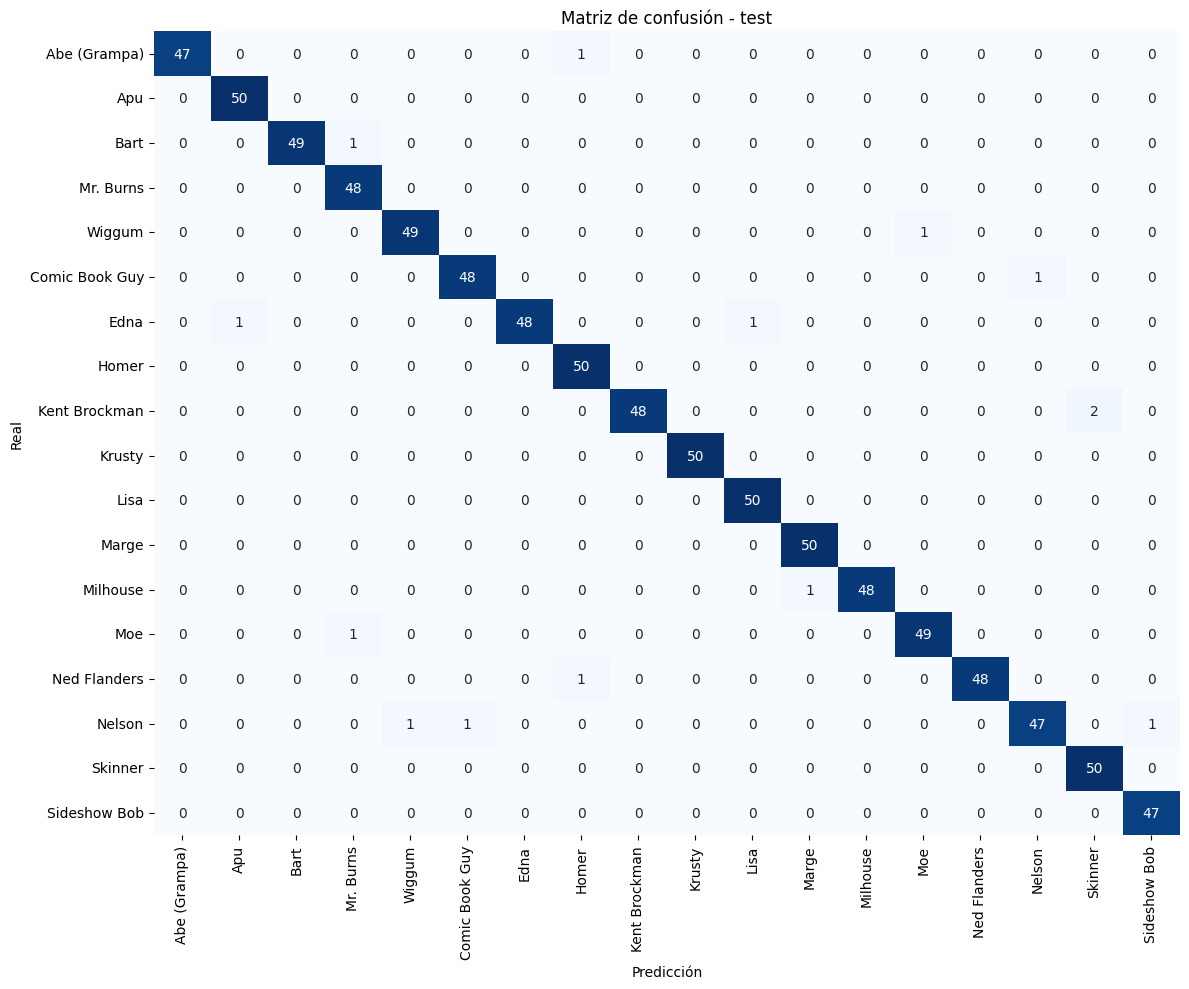

,real,predicho,errores test,errores validación
0,Bart,Lisa,0,13
1,Homer,Abe (Grampa),0,10
2,Abe (Grampa),Homer,1,8
3,Bart,Mr. Burns,1,5
4,Moe,Mr. Burns,1,5
5,Mr. Burns,Wiggum,0,5
6,Lisa,Bart,0,5
7,Comic Book Guy,Mr. Burns,0,4
8,Wiggum,Moe,1,3
9,Ned Flanders,Homer,1,3


Accuracy validación del mejor modelo: 0.9537


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=range(18))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=SHORT, yticklabels=SHORT, cbar=False)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - test")
plt.tight_layout(); plt.savefig(os.path.join("experimentos", "matriz_confusion_test.png"), dpi=90); plt.show()

# Pares de personajes que más se confunden (en test y en validación)
y_val_pred = best_model.predict(X_val, verbose=0).argmax(axis=1)
cm_val = confusion_matrix(y_val, y_val_pred, labels=range(18))
pares = [(SHORT[i], SHORT[j], cm[i, j], cm_val[i, j]) for i in range(18) for j in range(18) if i != j and (cm[i, j] + cm_val[i, j]) > 0]
pares = pd.DataFrame(pares, columns=["real", "predicho", "errores test", "errores validación"])
display(pares.sort_values(["errores validación", "errores test"], ascending=False).head(12).reset_index(drop=True))
print(f"Accuracy validación del mejor modelo: {(y_val_pred == y_val).mean():.4f}")

**Análisis por clase:**

- El modelo final comete **solo 14 errores de 890** en test. Krusty se clasifica perfectamente (F1 = 1,00) y todas las clases tienen *precision* ≥ 0,96 y *recall* ≥ 0,94.
- La clase con peor F1 es **Nelson (0,959, recall 0,94)**, justamente la que tiene **menos imágenes de entrenamiento** (358). Edna y Kent Brockman, también minoritarias (457 y 498 imágenes), tienen recall de 0,96: el desbalance se nota en el *recall* de las clases pequeñas.
- La menor *precision* la tienen **Mr. Burns (0,960)**, **Homer** y **Skinner (0,962)**: otras clases se clasifican erróneamente como ellos. Homer es la clase mayoritaria, por lo que el modelo tiende a elegirlo cuando duda.
- En validación (3.799 imágenes, más difíciles) los pares más confundidos son **Bart → Lisa (13 errores)**, **Homer → Abe (10)** y **Abe → Homer (8)**: personajes con forma de cabeza y colores muy parecidos (Homer y su padre son calvos con barba similar; Bart y Lisa tienen el pelo en puntas del mismo color). Les siguen, con 5 errores cada uno, Lisa → Bart, Bart → Mr. Burns, Moe → Mr. Burns y Mr. Burns → Wiggum.

## 9. Análisis visual de los errores

Errores en test: 14 de 890


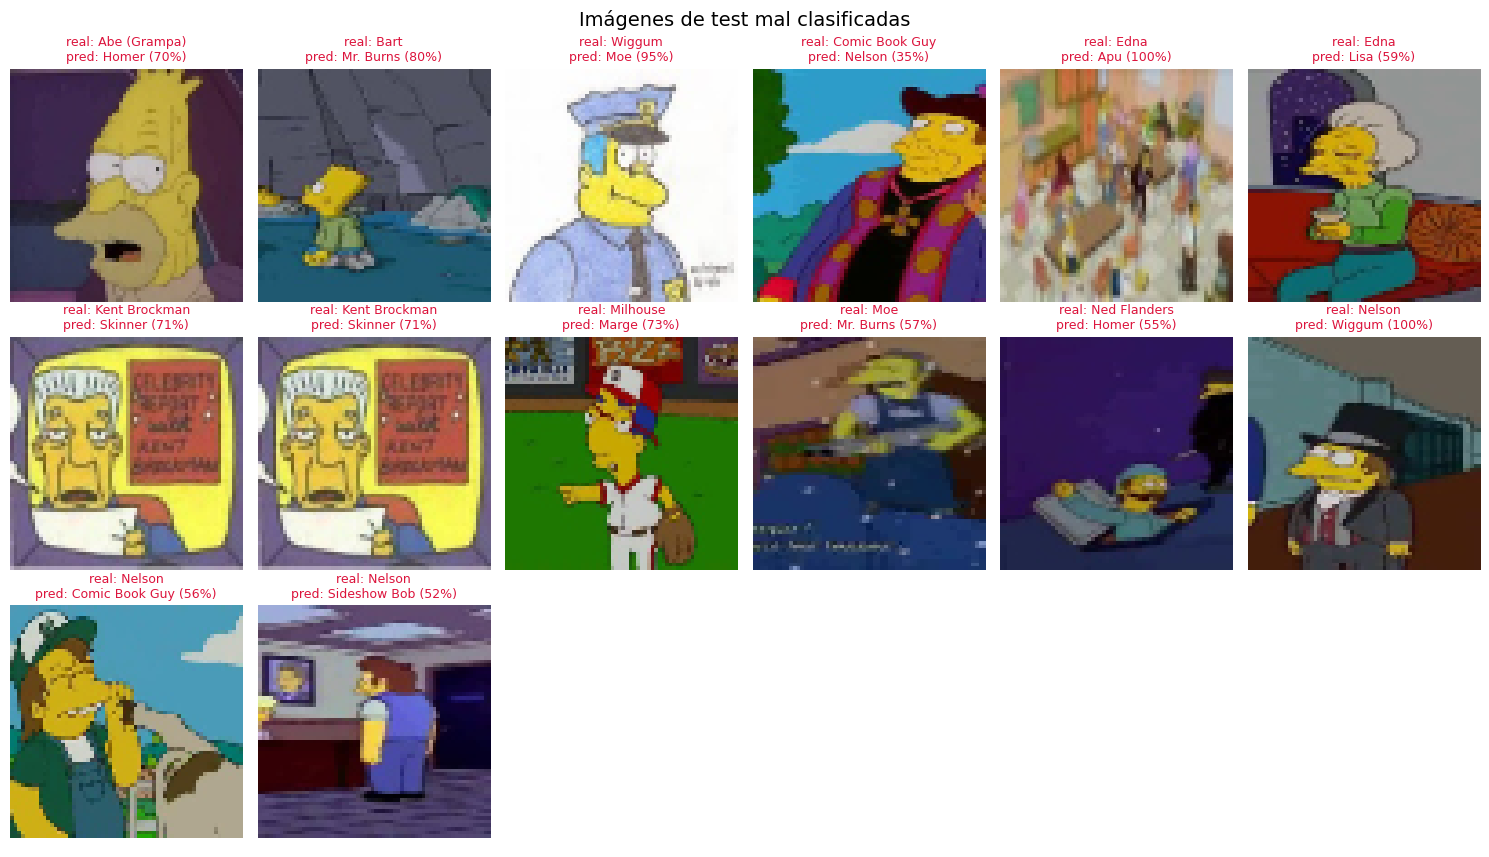

In [ ]:
err = np.where(y_pred != y_test)[0]
print(f"Errores en test: {len(err)} de {len(y_test)}")
n = len(err)
if n:
    cols = 6; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 2.9 * rows))
    for ax in np.array(axes).flat: ax.axis("off")
    for ax, i in zip(np.array(axes).flat, err):
        ax.imshow(X_t[i])
        ax.set_title(f"real: {SHORT[y_test[i]]}\npred: {SHORT[y_pred[i]]} ({y_prob[i].max():.0%})", fontsize=9, color="crimson")
    plt.suptitle("Imágenes de test mal clasificadas", fontsize=14); plt.tight_layout(); plt.show()

Errores en validación: 176 de 3799


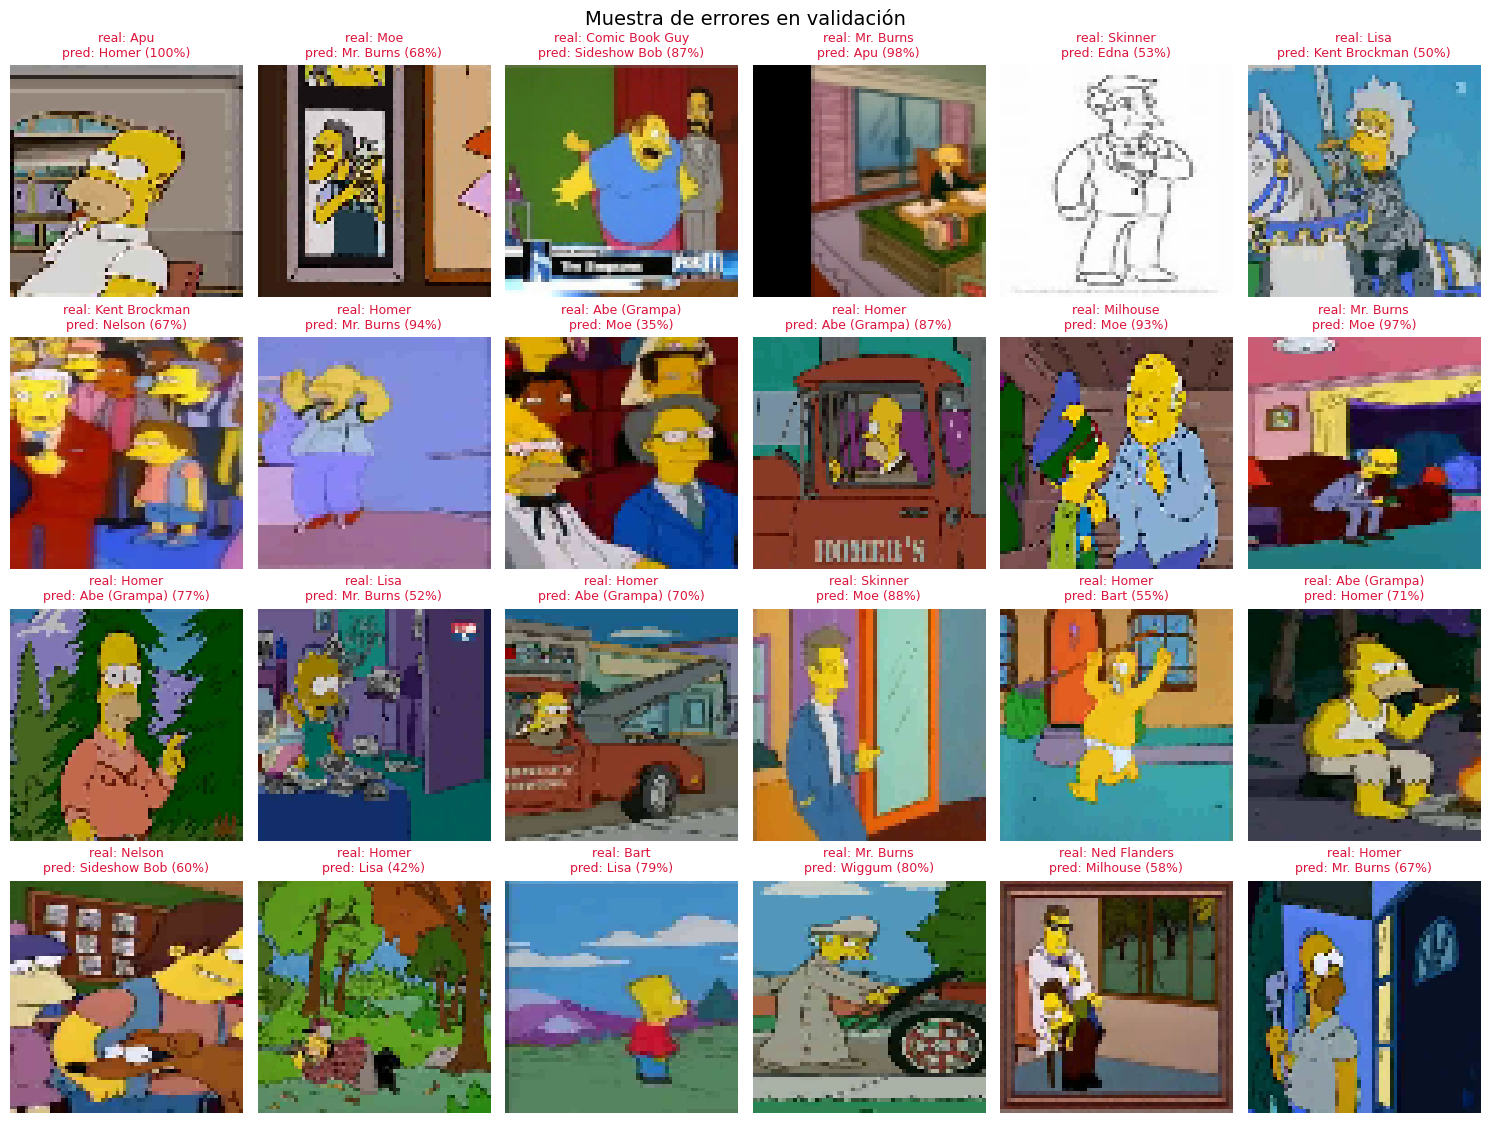

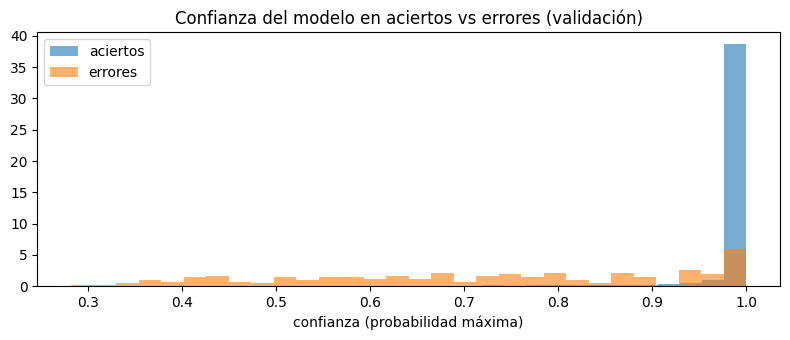

Confianza media aciertos: 0.98 | errores: 0.72


In [ ]:
# En validación hay más errores (imágenes más difíciles): miramos una muestra y la confianza del modelo
y_val_prob = best_model.predict(X_val, verbose=0)
err_v = np.where(y_val_pred != y_val)[0]
print(f"Errores en validación: {len(err_v)} de {len(y_val)}")
muestra = np.random.default_rng(SEED).choice(err_v, size=min(24, len(err_v)), replace=False)
fig, axes = plt.subplots(4, 6, figsize=(15, 11.5))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, muestra):
    ax.imshow(X_val[i])
    ax.set_title(f"real: {SHORT[y_val[i]]}\npred: {SHORT[y_val_pred[i]]} ({y_val_prob[i].max():.0%})", fontsize=9, color="crimson")
plt.suptitle("Muestra de errores en validación", fontsize=14); plt.tight_layout(); plt.show()

conf_ok = y_val_prob.max(axis=1)[y_val_pred == y_val]
conf_err = y_val_prob.max(axis=1)[y_val_pred != y_val]
plt.figure(figsize=(8, 3.5))
plt.hist(conf_ok, bins=30, alpha=.6, density=True, label="aciertos")
plt.hist(conf_err, bins=30, alpha=.6, density=True, label="errores")
plt.xlabel("confianza (probabilidad máxima)"); plt.legend(); plt.title("Confianza del modelo en aciertos vs errores (validación)")
plt.tight_layout(); plt.show()
print(f"Confianza media aciertos: {conf_ok.mean():.2f} | errores: {conf_err.mean():.2f}")

**Qué tipo de imágenes dan problemas:**

- **Personajes parecidos:** Abe confundido con Homer (70 % de confianza). A 64x64 el detalle que los distingue (arrugas, barba) prácticamente desaparece; en validación ocurre lo mismo con Bart y Lisa.
- **Personaje pequeño o escena oscura:** cuando el personaje ocupa una parte pequeña de la imagen (Bart en el agua, predicho como Mr. Burns con 80 %; Ned Flanders en una escena nocturna, predicho como Homer), el modelo se fija en otros elementos.
- **Estilo, ropa o contexto atípico:** Wiggum en un dibujo a lápiz sobre fondo blanco (predicho como Moe con 95 %), Comic Book Guy vestido de obispo y Milhouse con uniforme de béisbol (predicho como Marge). El modelo aprende en parte la ropa y el estilo habituales de cada personaje.
- **Imágenes borrosas o de baja calidad:** una escena de Edna muy desenfocada (predicha como Apu con 100 %) y una de Moe oscura y borrosa.
- **Posible ruido en las etiquetas:** varias imágenes etiquetadas como Nelson no muestran sus rasgos característicos (una se predice como Wiggum con 100 % de confianza). Además, el test contiene una imagen de Kent Brockman **duplicada**, que cuenta como dos errores.
- **El modelo "sabe" cuando duda:** la confianza media en los aciertos es 0,98 y en los errores 0,72; seis de los 14 errores de test tienen menos de 60 % de probabilidad. Esto permitiría marcar como "no seguro" las predicciones con baja confianza.

## 10. Conclusiones

- Se entrenó un clasificador CNN que alcanza **98,4 % de accuracy en el conjunto de test** (y 95,4 % en validación), superando ampliamente el objetivo del **85 %**. La *precision* es ≥ 0,96 y el *recall* ≥ 0,94 en las 18 clases.
- **Las CNN son claramente superiores a las redes Fully Connected** para imágenes: la FC no supera el 33 % aun teniendo 3 veces más parámetros, porque no aprovecha la estructura espacial ni comparte pesos.
- **La profundidad y la regularización son clave.** La CNN simple sobreajusta enseguida; agregar más bloques convolucionales con *batch normalization* y *dropout* subió la validación de 77 % a 95 % con prácticamente el mismo número de parámetros.
- **El *data augmentation* mejoró la generalización:** dio la mejor accuracy en validación y en test y redujo la brecha train–validación de 4,3 a 2,8 puntos, a cambio de necesitar más épocas.
- Los errores restantes se concentran en personajes visualmente similares (Homer/Abe, Bart/Lisa), en la clase con menos ejemplos (Nelson) y en imágenes difíciles (personaje pequeño, borroso o con ropa o estilo atípico).

**Posibles mejoras:** usar `class_weight` o sobremuestreo para compensar el desbalance; aumentar la resolución de entrada (96 o 128 px) para conservar más detalle; entrenar más épocas el modelo con *augmentation*, que aún no se había estancado; y aplicar *transfer learning* con una red preentrenada (p. ej. MobileNetV2 o EfficientNet).